# Fixing the run's record, number by number: a demo of `eval.py`

**Artifact `art_LzP2qPwUrANz`** (evaluation; iteration 7, Step 0) of a research run that asks how "creativity" shows up inside an open-weight LLM, and whether it can be steered. For example: asked to implement a path search, does the model always write BFS or Dijkstra? Where in the network is that choice held? Does banning the default in the prompt *substitute* another algorithm rather than just *subtract* one?

**What the original `eval.py` does.** It repairs the iteration-6 record of the run report before the paper quotes it. Four iteration-6 experiments are covered: engine control `art_lpQalcAXMGr1`, the exchange and site experiment `art_rMlbrjVB1c__`, Gemma `art_zNyBP6zieI5u`, and NLA `art_dbUtqBjT0tPf`. Every number the report prints about them is re-derived from their raw rows (items **0a–0l**). Each fix becomes a verbatim `old_text -> new_text` pair marked `(iteration-7 correction)`. The script then:
1. proves that every pair applies exactly once to a copy of the report, with no overlapping spans (the **apply test**);
2. writes the corrected report and its unified diff;
3. lints the corrected prose for leftover wrong claims (the **residual-claim lint**);
4. gives every value a status (`MATCH`, `NEW`, `CARRIED` or `CORRECTED`) by comparing the number the report printed with the one recomputed from raw rows;
5. writes tables and `eval_out.json` (metrics M1–M12), and runs two independent standard-library audits.

**What this notebook runs.** The items themselves are not re-run here. They read about 40 MB of raw rows, three paid LLM judges and a live web pass. Instead, the notebook loads two things from `mini_demo_data.json`:
- the 54 corrections that the items registered (the `corrections` dataset of `full_eval_out.json`);
- the 151 report lines that those corrections touch, plus the `# References` heading, all kept at their original line numbers.

It then runs the rest of `eval.py` on them, using the original code of `src/corrections.py`, `src/stats.py` and `src/outputs.py`. The steps are the registry, the apply test, the diff, the lint, the value statuses, the tables and metrics M1/M2. At the end come plots of where the corrections land, and a re-derivation of the headline statistics with the artifact's own `stats.py`.

**Key results recorded by the full run** (re-checked below where the demo data allows):
- 54 corrections; the apply test passes 54/54 with no overlaps. Lint flags fall from 16 to 0.
- Values: 603 MATCH, 117 NEW, 1 CARRIED and 3 CORRECTED. The 3 corrected values are venue expectations of the plan that the live records contradict.
- **0a.** The Stage A tables print commit0's *attempted* share, where invalid rows count as not-Y. They do not print "the share of correct programs". For shortest path, blocks 0–35, the counts are 24/30 attempts against 21/30 correct programs. Five cells fail the pass-ratio gate (≥ 0.8).
- **0h.** The NLA test reproduces at the unit level (364 units, 20:88, p 2.3e-11). With one unit per sample it still holds per sample, but it is inconclusive at the task level: with 5 task clusters the smallest attainable p is 0.0625.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru: NOT on Colab, always install (eval.py logs through it; version pinned in the artifact's pyproject.toml)
_pip('loguru==0.7.3')

# numpy, scipy, pandas, matplotlib: pre-installed on Colab, install locally only (Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'pandas==2.2.2', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# --- original import block of eval.py ---
import argparse
import csv
import json
import resource
import subprocess
import sys
import time
from pathlib import Path

from loguru import logger

# --- imports of the src/ modules inlined below (common.py, stats.py, corrections.py, outputs.py) ---
import copy
import difflib
import hashlib
import math
import os
import re
from dataclasses import asdict, dataclass, field
from typing import Any, Iterable, Sequence

import numpy as np
from scipy import stats as st

# --- notebook-only additions (tables and plots) ---
from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-7/evaluation-6/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
examples = data["datasets"][0]["examples"]  # the 'corrections' dataset of full_eval_out.json
print(f"dataset '{data['datasets'][0]['dataset']}': {len(examples)} corrections; report excerpt: "
      f"{data['metadata']['report']['n_excerpt_lines']} of {data['metadata']['report']['n_lines']} lines")

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
dataset 'corrections': 54 corrections; report excerpt: 152 of 6345 lines


## Configuration

The original run has one switch, `--stages`. With `all`, it re-calls the paid judges and the live web pass; with `offline`, it reuses their cached results. This demo matches `--stages offline`, limited to the correction pipeline.

Its only knob is `MAX_CORRECTIONS`: how many of the registered corrections to replay, in registration order. The full run has 54, and with 1 the pipeline still produces output. The whole pipeline takes well under a second, so the full count is used.

`OUT_DIR` is where the demo writes the files that `eval.py` writes into its workspace: the corrected report, the diff, `corrections.json`, the values ledger, the CSV tables and `eval_out.json`.

In [5]:
# How many of the registered corrections to replay, in registration order (C7-01, C7-02, ...).
MAX_CORRECTIONS = 54        # = the full run (all 54); the minimum that produces output is 1 (tested with 2)
# Where the demo writes what eval.py writes into its workspace folder.
OUT_DIR = Path("eval_demo_out")
# How many lines of the unified diff to print in the results.
DIFF_PREVIEW_LINES = 40

## Shared constants and helpers (`src/common.py`)

These are copied from `src/common.py`, with two changes:
- The workspace anchor `WS`, and the `tables/`, `logs/` and `results/` folders under it, point at `OUT_DIR` instead of the artifact folder.
- The dependency lookup (`DEPS_ROOT`, `dep_dir`, `inp`, the hashing of the 69 vendored inputs) is left out, because the inputs come from `mini_demo_data.json`.

`MARK` is the marker that every corrected text must carry exactly once. `READ_DATE` is the date the report was read.

In [6]:
# src/common.py: paths re-pointed at OUT_DIR (was: WS = Path(__file__).resolve().parents[1])
WS = OUT_DIR
TABLES = WS / "tables"
AUDIT = WS / "audit"
LOGS = WS / "logs"
RESULTS = WS / "results"
READ_DATE = "2026-10-22"
MARK = "(iteration-7 correction)"


def setup_logging(name: str) -> None:
    LOGS.mkdir(parents=True, exist_ok=True)
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(LOGS / f"{name}.log", rotation="30 MB", level="DEBUG")


def read_json(p: Path) -> Any:
    return json.loads(Path(p).read_text())


def write_json(p: Path, obj: Any, indent: int = 1) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    p.write_text(json.dumps(obj, indent=indent, default=_default, ensure_ascii=False) + "\n")


def _default(o: Any) -> Any:
    try:
        import numpy as np
        if isinstance(o, np.integer):
            return int(o)
        if isinstance(o, np.floating):
            return float(o)
        if isinstance(o, np.ndarray):
            return o.tolist()
        if isinstance(o, np.bool_):
            return bool(o)
    except ImportError:
        pass
    if isinstance(o, Path):
        return str(o)
    if isinstance(o, set):
        return sorted(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode()).hexdigest()


def fmt(x: float | None, nd: int = 2) -> str:
    if x is None:
        return "n/a"
    return f"{x:.{nd}f}"


def fmt_p(p: float | None) -> str:
    """Report-style p value: 3 significant digits above 1e-3, scientific below."""
    if p is None:
        return "n/a"
    if p >= 0.001:
        return f"{p:.3f}" if p < 0.1 else f"{p:.2f}"
    return f"{p:.1e}"

## Exact small-sample statistics (`src/stats.py`, verbatim)

This cell holds the artifact's exact tests:
- Clopper–Pearson intervals;
- the exact two-sided binomial and McNemar tests;
- the sign test and the smallest p it can reach with n clusters;
- the Durkalski cluster-adjusted McNemar;
- Wilson intervals, Cohen's kappa and the cluster bootstrap.

In the full run, items 0a, 0h and 0i call these functions on raw rows. The last section of this notebook calls them on the counts the full run recorded.

In [7]:
"""Exact small-sample statistics used by the record repair (scipy where it is exact, closed forms otherwise)."""


def clopper_pearson(k: int, n: int, alpha: float = 0.05) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    lo = 0.0 if k == 0 else float(st.beta.ppf(alpha / 2, k, n - k + 1))
    hi = 1.0 if k == n else float(st.beta.ppf(1 - alpha / 2, k + 1, n - k))
    return (lo, hi)


def binom_two_sided(k: int, n: int, p0: float = 0.5) -> float:
    """Exact two-sided binomial test (minimum-likelihood method, as scipy.stats.binomtest)."""
    if n == 0:
        return 1.0
    return float(st.binomtest(k, n, p0, alternative="two-sided").pvalue)


def mcnemar_exact(b: int, c: int) -> float:
    """Exact McNemar: two-sided binomial test of b against b + c at 0.5."""
    return binom_two_sided(b, b + c, 0.5) if b + c else 1.0


def mcnemar_from_pairs(xs: Sequence[int], ys: Sequence[int]) -> dict:
    b = sum(1 for x, y in zip(xs, ys) if x == 1 and y == 0)
    c = sum(1 for x, y in zip(xs, ys) if x == 0 and y == 1)
    n = len(xs)
    return {"n": n, "b": b, "c": c, "p": mcnemar_exact(b, c),
            "effect": (sum(xs) - sum(ys)) / n if n else None}


def sign_test(diffs: Sequence[float]) -> dict:
    pos = sum(1 for d in diffs if d > 0)
    neg = sum(1 for d in diffs if d < 0)
    return {"n_pos": pos, "n_neg": neg, "n_zero": sum(1 for d in diffs if d == 0),
            "p": binom_two_sided(pos, pos + neg) if pos + neg else 1.0}


def sign_test_floor(n_clusters: int) -> float:
    """Smallest attainable two-sided p of an exact sign test over n clusters (all n in one direction)."""
    return min(1.0, 2.0 * 0.5 ** n_clusters)


def durkalski_mcnemar(clusters: dict[str, tuple[int, int]]) -> dict:
    """Durkalski et al. (2003) cluster-adjusted McNemar statistic.

    clusters maps a cluster id to (b_k, c_k), its counts of (x=1, y=0) and (x=0, y=1) pairs. The statistic is
    (B - C)^2 / sum_k (b_k - c_k)^2, referred to chi-square with 1 df (asymptotic; reported as a sensitivity).
    """
    B = sum(b for b, _ in clusters.values())
    C = sum(c for _, c in clusters.values())
    den = sum((b - c) ** 2 for b, c in clusters.values())
    if den == 0:
        return {"B": B, "C": C, "chi2": None, "p": None, "n_clusters": len(clusters)}
    chi2 = (B - C) ** 2 / den
    return {"B": B, "C": C, "chi2": chi2, "p": float(st.chi2.sf(chi2, 1)), "n_clusters": len(clusters)}


def wilson(k: int, n: int, z: float = 1.959963984540054) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    ph = k / n
    den = 1 + z * z / n
    c = (ph + z * z / (2 * n)) / den
    h = z * math.sqrt(ph * (1 - ph) / n + z * z / (4 * n * n)) / den
    return (c - h, c + h)


def cohen_kappa(a: Sequence[str], b: Sequence[str]) -> float | None:
    if not a or len(a) != len(b):
        return None
    cats = sorted(set(a) | set(b))
    n = len(a)
    po = sum(1 for x, y in zip(a, b) if x == y) / n
    pe = sum((sum(1 for x in a if x == c) / n) * (sum(1 for y in b if y == c) / n) for c in cats)
    if pe >= 1.0:
        return 1.0 if po == 1.0 else 0.0
    return (po - pe) / (1 - pe)


def cluster_bootstrap_mean_diff(units: list[dict], key: str = "task", n_boot: int = 2000,
                                seed: int = 20261022) -> list[float]:
    """Percentile interval of mean(x) - mean(y), resampling clusters with replacement (as the NLA artifact)."""
    clusters: dict = {}
    for u in units:
        clusters.setdefault(u[key], []).append(u)
    keys = sorted(clusters)
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(n_boot):
        pick = rng.choice(len(keys), size=len(keys), replace=True)
        s = [u for i in pick for u in clusters[keys[i]]]
        if s:
            vals.append(float(np.mean([u["x"] for u in s]) - np.mean([u["y"] for u in s])))
    return [float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))]

## Correction registry, value statuses, apply test and lint (`src/corrections.py`, verbatim)

- **`V(...)` and `status_of(...)`.** Each value has a *recorded* number (what the report printed, or `None`) and a *recomputed* one. Its status is one of four:
  - `NEW`: nothing was recorded.
  - `CARRIED`: the value could not be recomputed and is carried from the record.
  - `MATCH`: the two agree within tolerance. The tolerance is 0 for counts, 0.005 for proportions, 0.01 for intervals, effects and ratios, 1 % relative for p-values, and exact equality for text.
  - `CORRECTED`: the two disagree.
- **`Registry.add(...)`** numbers each correction `C7-xx`, records the line where its `old_text` starts (`line_at_read`), and appends the marker if it is missing.
- **`apply_all(...)`** is the apply test. Each `old_text` must occur exactly once in the uncorrected report; the new text must be present afterwards; the marker must appear exactly once; and no two corrected spans may overlap. The corrections are applied in file order. An `insert_after` keeps its anchor and inserts the new block after it.
- **`lint(...)`** runs regexes for leftover wrong claims from line 5497 (the start of the iteration-6 sections) up to `# References`. Two examples are a Stage A share quoted without its "of 30", and "every edit … breaks programs".

In [8]:
"""A3/A4: the correction registry, value statuses, the apply test and the residual-claim lint (M1, M2).

A correction is {id 'C7-xx', item, section, table, line_at_read, kind, old_text, new_text, values, rationale}.
kind is replace | insert_after | table_replace. For insert_after, old_text is the unique anchor and the new text
is inserted after it (the stored new_text is the inserted block only). Every new_text carries the marker
'(iteration-7 correction)' exactly once. Numbers in new_text come from recomputed values by template.
"""

TOL = {"count": 0.0, "prop": 0.005, "effect": 0.01, "ci": 0.01, "p": None, "text": None, "ratio": 0.01}


def status_of(recorded: Any, recomputed: Any, tol: str) -> str:
    if recorded is None:
        return "NEW"
    if recomputed is None:
        return "CARRIED"
    if tol == "text":
        return "MATCH" if str(recorded) == str(recomputed) else "CORRECTED"
    if isinstance(recorded, (list, tuple)):
        ok = all(abs(float(a) - float(b)) <= TOL["ci"] + 1e-12 for a, b in zip(recorded, recomputed))
        return "MATCH" if ok and len(recorded) == len(recomputed) else "CORRECTED"
    r, c = float(recorded), float(recomputed)
    if tol == "p":
        if r < 1e-6 and c < 1e-6:
            return "MATCH"
        return "MATCH" if abs(r - c) <= 0.01 * max(abs(r), 1e-300) else "CORRECTED"
    return "MATCH" if abs(r - c) <= TOL[tol] + 1e-12 else "CORRECTED"


def V(name: str, recomputed: Any, recorded: Any = None, *, tol: str = "count", source: str = "",
      carried: bool = False, printed: Any = None) -> dict:
    st = "CARRIED" if carried else status_of(recorded, recomputed, tol)
    out = {"name": name, "recorded": recorded, "recomputed": recomputed, "status": st, "tolerance": tol,
           "source": source}
    if printed is not None:
        out["printed_in_report"] = printed
    return out


@dataclass
class Correction:
    id: str
    item: str
    section: str
    table: str | None
    line_at_read: int | None
    kind: str
    old_text: str
    new_text: str
    values: list[dict] = field(default_factory=list)
    rationale: str = ""
    also_items: list[str] = field(default_factory=list)


class Registry:
    def __init__(self, report: str):
        self.report = report
        self.items: list[Correction] = []
        self.discrepancies: list[dict] = []

    def line_of(self, text: str) -> int | None:
        i = self.report.find(text)
        return None if i < 0 else self.report.count("\n", 0, i) + 1

    def add(self, *, item: str, section: str, kind: str, old_text: str, new_text: str, values: list[dict],
            rationale: str, table: str | None = None, also_items: list[str] | None = None) -> Correction:
        assert kind in ("replace", "insert_after", "table_replace"), kind
        if MARK not in new_text:
            new_text = new_text.rstrip() + " " + MARK
        cid = f"C7-{len(self.items) + 1:02d}"
        c = Correction(id=cid, item=item, section=section, table=table, line_at_read=self.line_of(old_text),
                       kind=kind, old_text=old_text, new_text=new_text, values=values, rationale=rationale,
                       also_items=also_items or [])
        self.items.append(c)
        for v in values:
            if v["status"] == "CORRECTED":
                self.discrepancies.append({"correction": cid, **v})
        return c

    def as_dicts(self) -> list[dict]:
        return [asdict(c) for c in self.items]


def apply_all(report: str, corrections: list[dict]) -> tuple[str, dict]:
    """Apply in file order (by position of old_text in the uncorrected report) and check the contract."""
    checks = []
    for c in corrections:
        n = report.count(c["old_text"])
        checks.append({"id": c["id"], "old_found_exactly_once": n == 1, "n_found": n,
                       "marker_once": c["new_text"].count(MARK) == 1})
    # overlap check on spans in the uncorrected report
    spans = []
    for c in corrections:
        i = report.find(c["old_text"])
        if i >= 0:
            spans.append((i, i + len(c["old_text"]), c["id"]))
    spans.sort()
    overlaps = [(a[2], b[2]) for a, b in zip(spans, spans[1:]) if b[0] < a[1]]
    order = sorted(corrections, key=lambda c: report.find(c["old_text"]))
    out = report
    for c in order:
        if out.count(c["old_text"]) != 1:
            continue
        if c["kind"] == "insert_after":
            out = out.replace(c["old_text"], c["old_text"] + c["new_text"], 1)
        else:
            out = out.replace(c["old_text"], c["new_text"], 1)
    for ch in checks:
        c = next(x for x in corrections if x["id"] == ch["id"])
        ch["new_present_after"] = c["new_text"] in out
        ch["pass"] = ch["old_found_exactly_once"] and ch["new_present_after"] and ch["marker_once"]
    n_pass = sum(ch["pass"] for ch in checks)
    res = {"n": len(checks), "n_pass": n_pass, "pass_rate": n_pass / len(checks) if checks else None,
           "overlaps": overlaps, "checks": checks, "passed": n_pass == len(checks) and not overlaps}
    return out, res


def unified_diff(a: str, b: str) -> str:
    return "".join(difflib.unified_diff(a.splitlines(keepends=True), b.splitlines(keepends=True),
                                        fromfile="current_report.md", tofile="report_corrected.md", n=1))


# ---------------------------------------------------------------- M2: residual-claim lint
STAGEA_CTX = re.compile(r"exchang|Stage A|task-specification states|transfer", re.I)
STAGEA_NUM = re.compile(r"(?<![\d.])0\.(?:80|57|47|33|567|467|333)(?!\d)")
LINT = {
    "post_hoc_form_survives": re.compile(r"post-hoc form survives", re.I),
    "measured_in_three_models": re.compile(r"measured in three models", re.I),
    "in_all_three_read_position": re.compile(r"In all three (models )?the read position", re.I),
    "essentially_one_direction": re.compile(r"essentially one direction", re.I),
    "every_edit_pass_or_breaks": re.compile(r"every (fork )?edit[^.]{0,80}?(pass rate|breaks)", re.I),
    "post_hoc_ordering_noise_sites": re.compile(r"post-hoc ordering of noise sites", re.I),
}
TOP5 = re.compile(r"(top-five (direction|push)|activation version of the prohibition)[^.]*breaks programs before",
                  re.I)


def _sentences(par: str) -> list[str]:
    return re.split(r"(?<=[.;])\s+(?=[A-Z*(])", par)


def lint(text: str, start_line: int = 5497) -> list[dict]:
    """Flag leftover wrong claims in iteration-6 prose (Sections 6.4 to the closing). Table rows are skipped
    for the Stage A share check (their captions and columns carry the definitions)."""
    hits = []
    lines = text.splitlines()
    end = next((i for i, l in enumerate(lines) if l.startswith("# References")), len(lines))
    for ln in range(start_line - 1, end):
        line = lines[ln]
        if MARK in line and "*(Correction, iteration 6" not in line:
            pass
        for name, rx in LINT.items():
            for m in rx.finditer(line):
                hits.append({"line": ln + 1, "rule": name, "snippet": line[max(0, m.start() - 60):m.end() + 60]})
        for m in TOP5.finditer(line):
            a = line.rfind(". ", 0, m.start())
            b = line.find(".", m.end())
            seg = line[a + 1 if a >= 0 else 0: b + 1 if b > 0 else len(line)]
            if "ban unit" not in seg:
                hits.append({"line": ln + 1, "rule": "top5_without_ban_units", "snippet": seg[:200]})
        if line.startswith("|"):
            continue
        for s in _sentences(line):
            if STAGEA_NUM.search(s) and STAGEA_CTX.search(s) and "of 30" not in s and "Table" not in s[:12]:
                if re.search(r"noise|alpha|Spearman|odds ratio|escape", s, re.I):
                    continue
                hits.append({"line": ln + 1, "rule": "stageA_share_without_of_30", "snippet": s[:220]})
    return hits

## `eval.py`: item rationales and the memory cap

`RATIONALE` maps each item to the reason recorded with its corrections. `set_limits()` caps the address space at 24 GB, as in the original run.

Two functions of `eval.py` are not reproduced: `table278_row` and `positioning_row`. They build the new rows of Table 278 (the blind-judged engine-control programs) and Table 277 (the quote-verified positioning row) from the judge and web results. Their output is already in corrections C7-21 and C7-22 of the demo data.

In [9]:
RATIONALE = {
    "0a": "Stage A outcome returned to commit0's definition (attempted share, invalid as not-Y, pass-ratio gate) with a "
          "correct-Y count beside every share",
    "0b": "the site of the choice stated as open: the condition-span clause fails post hoc; the 'FP8-specific' label "
          "cannot apply",
    "0c": "Gemma's DAS and readout stated within the controls they had",
    "0d": "per-model, per-quantity synthesis in place of one cross-model map",
    "0e": "captioned [FIGURE] markers for the activation-space geometry plots",
    "0f": "top-five push dose caveat (1 to 8 ban units overshoot the forced-prompt manifold)",
    "0g": "correct-only columns for Table 238 and the MIXED screen-level verdict",
    "0h": "NLA per-sample test quoted with its clustered interval and at one unit per sample",
    "0i": "checks that ran but were never reported, and the judged engine-control programs",
    "0j": "Section 4.9 limited to the pools actually audited",
    "0k": "quote-verified positioning row for the one-token fork",
    "0l": "iteration-5 verdicts tagged as conditional",
}


def set_limits() -> None:
    resource.setrlimit(resource.RLIMIT_AS, (24 * 1024 ** 3, 24 * 1024 ** 3))

## Step 1. Inputs: the report being corrected

In `eval.py`, `main()` first resolves and sha256-hashes the 69 input files (`stage_inputs.resolve_all`). It then reads the 1 MB report `inputs/report/current_report.md`, and the iteration-6 copy of the report that item 0j diffs against.

Here the report is rebuilt from the excerpt in `mini_demo_data.json`. It holds the 151 lines that the corrections touch, plus the `# References` heading: 152 lines, each at its original line number. Every other line is blank. The line numbers are therefore those of the real report. Two parts of the code depend on that: `Registry.line_of`, and `lint`, which starts at line 5497. The cell also checks the excerpt's sha256 against the one recorded when the excerpt was cut.

In [10]:
setup_logging("eval")
set_limits()
t_start, cpu0 = time.time(), time.process_time()
# was: hashes = resolve_all(); report = (INPUTS / "report" / "current_report.md").read_text()
rep_meta = data["metadata"]["report"]
report_lines = [""] * rep_meta["n_lines"]
for ln, text in rep_meta["lines"].items():
    report_lines[int(ln) - 1] = text  # every kept line goes back to its original (1-based) line number
report = "\n".join(report_lines)
logger.info(f"report excerpt: {len(rep_meta['lines'])} of {rep_meta['n_lines']} lines, sha256 as recorded: "
            f"{sha256_text(report) == rep_meta['excerpt_sha256']}")
reg = Registry(report)

12:46:52|INFO   |report excerpt: 152 of 6345 lines, sha256 as recorded: True


## Step 2. Items 0a–0l: replay the registered corrections

In the full run, each item recomputes its numbers and registers corrections in one of two ways:
- directly, through `ed.whole` or `ed.insert` and then `Registry.add`. These are table rewrites and inserted rows or markers, C7-01 to C7-22.
- as paragraph edits that `ed.flush` hands to `Registry.add` at the end. These are C7-23 to C7-54.

| item | what it re-derives | read from |
|-|-|-|
| 0a | Stage A metric: commit0's attempted share beside correct-Y counts, the pass-ratio gate, a post-hoc McNemar | `art_rMlbrjVB1c__`: `data/labels.jsonl`, `results/stage_a.json`, `predictions/commit0.json` |
| 0b | site of the choice: condition-span betas, noise/exchange concordance (new Table 254b) | `art_rMlbrjVB1c__`: `results/site_grid.json` |
| 0c | Gemma DAS and readout, stated within the controls they had | `art_zNyBP6zieI5u`: `results/das.json`, `readout.json`, `clamps.json` |
| 0d | per-model, per-quantity synthesis (new Table 279) | items 0a, 0c, 0h |
| 0e | captioned `[FIGURE]` markers for the activation-space geometry plots | figure files (sha256, PDF text) and their plotting code |
| 0f | top-five push dose caveat | `art_rMlbrjVB1c__`: `results/top5_push.json` |
| 0g | correct-only columns of Table 238 | `art_lpQalcAXMGr1`: `data/samples.jsonl`, `results/pn.json` |
| 0h | NLA test at one unit per sample | `art_dbUtqBjT0tPf`: `data/judgements.jsonl`, `data/labels.jsonl`, `cache/states_index.jsonl` |
| 0i | U6 and D12, and the blind-judged engine-control programs | `art_zNyBP6zieI5u`: `results/fork.json`, `deviations.json`; LLM judges |
| 0j | Section 4.9 limited to the audited pools | diff against the iteration-6 report |
| 0k | quote-verified positioning row (Table 277) | arXiv pages and searches (cached web pass) |
| 0l | conditional tags on six iteration-5 verdicts | the report |

Here the registered corrections come from the data. They pass through the same `Registry.add` in the same order, so the IDs and `line_at_read` are re-derived from the excerpt. The cell checks that they equal the recorded ones.

In [11]:
# was: ed = Editor(report, reg); A = Q.item_0a(ed, report); B = Q.item_0b(ed, report, A["cells"]); ...
#      ... L = O.item_0l(ed); figs = build_figs(); ed.insert(...); ed.whole(old278, ...); ed.flush(RATIONALE)
# The items read raw rows that are not in the demo data: their registered corrections are replayed instead.
for e in examples[:MAX_CORRECTIONS]:
    reg.add(item=e["metadata_item"], section=e["metadata_section"], kind=e["metadata_kind"], old_text=e["input"],
            new_text=e["output"], values=e["metadata_values"], rationale=e["metadata_rationale"],
            table=e["metadata_table"], also_items=e["metadata_also_items"])
corr = reg.as_dicts()
same = sum(c["id"] == e["metadata_id"] and c["line_at_read"] == e["metadata_line_at_read"] and c["new_text"] == e["output"]
           for c, e in zip(corr, examples))
logger.info(f"replayed {len(corr)} corrections; id, line_at_read and new_text as recorded: {same}/{len(corr)}")
display(pd.DataFrame([{"id": c["id"], "item": c["item"], "kind": c["kind"], "section": c["section"],
                       "table": c["table"], "line_at_read": c["line_at_read"], "n_values": len(c["values"]),
                       "old chars": len(c["old_text"]), "new chars": len(c["new_text"])} for c in corr]))

12:46:52|INFO   |replayed 54 corrections; id, line_at_read and new_text as recorded: 54/54


,id,item,kind,section,table,line_at_read,n_values,old chars,new chars
0,C7-01,0a,table_replace,6.4.1,Table 244,5509,10,2034,2718
1,C7-02,0a,table_replace,6.4.1,Table 245,5524,10,1746,2422
2,C7-03,0a,table_replace,6.4.1,Table 246,5539,10,1826,2506
3,C7-04,0a,table_replace,6.4.1,Table 247,5554,7,1223,1717
4,C7-05,0a,table_replace,6.4.1,Table 248,5566,7,1328,1823
5,C7-06,0a,table_replace,6.4.1,Table 249,5578,7,1269,1763
6,C7-07,0a,table_replace,6.4.1,Table 250,5594,36,2210,2586
7,C7-08,0b,insert_after,6.4.2,Table 254b,5711,0,68,1156
8,C7-09,0g,table_replace,6.3,Table 238,5408,64,1142,1728
9,C7-10,0h,replace,6.6,Table 270,5981,0,138,454


## Step 3. Apply test, corrected report, diff and lint

This block is copied from `eval.py`:
- `apply_all` applies the corrections in file order and checks the contract for each one.
- The corrected report and its unified diff are written to disk.
- `lint` runs on the uncorrected text and on the corrected text.
- `cons` is the consistency check of the new Table 277 row (item 0k). The row must not say "readable across prompts", and it must carry the next-token qualifier.

One step is skipped: `Q.occurrence_ledger`, which classifies every occurrence of 0.80, 0.57, 0.47 and 0.33 in the *full* report. It needs the lines that this excerpt blanks.

In [12]:
# ---- apply test, diff, lint, ledger, consistency
corrected, apply_res = apply_all(report, corr)
(WS / "report_corrected.md").write_text(corrected)
(WS / "report.diff").write_text(unified_diff(report, corrected))
lint_before, lint_after = lint(report), lint(corrected)
changed_lines = {c["line_at_read"]: c["id"] for c in corr if c["line_at_read"]}
# ledger = Q.occurrence_ledger(report, changed_lines)  # needs every line of the full report (skipped)
row = next((c["new_text"] for c in corr if c["item"] == "0k"), "")  # was: anchor, row = positioning_row(pos, GE)
cons = {"row_has_readable_across_prompts": "readable across prompts" in row,
        "row_has_next_token_qualifier": "next-token readout" in row}
cons["passed"] = (not cons["row_has_readable_across_prompts"]) and cons["row_has_next_token_qualifier"]
logger.info(f"apply test {apply_res['n_pass']}/{apply_res['n']} (overlaps: {apply_res['overlaps']}, passed: "
            f"{apply_res['passed']}); lint {len(lint_before)} -> {len(lint_after)}; 0k consistency: {cons}")

12:46:52|INFO   |apply test 54/54 (overlaps: [], passed: True); lint 16 -> 0; 0k consistency: {'row_has_readable_across_prompts': False, 'row_has_next_token_qualifier': True, 'passed': True}


## Step 4. Value statuses

Every correction carries the values it was built from. `eval.py` pools them with the value blocks the items return (`A["values"]`, `B["values"]`, …), drops duplicates by (name, source, recomputed value), and counts the statuses. `CORRECTED` values become the run's discrepancies.

The item blocks are not in the demo data, so the demo pools the corrections' values only. Its counts are therefore a subset of the full run's 603 MATCH, 117 NEW, 1 CARRIED and 3 CORRECTED.

One extra check is added here: `status_of` is re-run on each value's recorded number, recomputed number and tolerance, and the result is compared with the stored status.

In [13]:
# ---- statuses
all_vals = []
for c in corr:
    all_vals += c["values"]
# for blk in (A["values"], B["values"], G8["values"], GE["values"], H["values"], F["values"], U["values"], J["values"]):
#     all_vals += blk  # the items' own value blocks need the raw rows (not in the demo data)
seen, uniq = set(), []
for v in all_vals:
    key = (v["name"], v["source"], json.dumps(v["recomputed"], default=str))
    if key not in seen:
        seen.add(key)
        uniq.append(v)
all_vals = uniq
by_status = {}
for v in all_vals:
    by_status[v["status"]] = by_status.get(v["status"], 0) + 1
discrepancies = [  # was: A["discrepancies"] + G8["discrepancies"] + [...]
    {k: v[k] for k in ("name", "recorded", "recomputed", "source")} for v in all_vals if v["status"] == "CORRECTED"]
# demo check: the status rule of src/corrections.py gives back every stored status
rederived = sum(status_of(v["recorded"], v["recomputed"], v["tolerance"]) == v["status"] for v in all_vals)
logger.info(f"{len(all_vals)} unique values in the replayed corrections: {by_status}; status_of reproduces "
            f"{rederived}/{len(all_vals)}; full run, all blocks: {data['metadata']['full_run']['value_statuses_all_blocks']}")

12:46:52|INFO   |183 unique values in the replayed corrections: {'MATCH': 146, 'NEW': 33, 'CARRIED': 1, 'CORRECTED': 3}; status_of reproduces 183/183; full run, all blocks: {'MATCH': 603, 'NEW': 117, 'CARRIED': 1, 'CORRECTED': 3}


## Step 5. `corrections.json`, the values ledger and the tables

These writes follow `eval.py`, minus the files that need the items: `figure_markers.json`, `results/items.json`, and the Stage A, Table 238 and NLA tables. The report hash written into `corrections.json` is the recorded sha256 of the full report, since only an excerpt is available here.

In [14]:
write_json(WS / "corrections.json", {"read_date": READ_DATE, "report_sha256": rep_meta["sha256_full_report"],
           "n": len(corr), "corrections": corr, "apply_test": apply_res,
           "editor_problems": []})  # was: sha256_file(INPUTS / "report" / "current_report.md") and ed.problems
write_json(WS / "results" / "values_ledger.json", all_vals)
TABLES.mkdir(exist_ok=True)
with (TABLES / "corrections_index.csv").open("w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["id", "item", "also_items", "section", "table", "line_at_read", "kind", "n_values"])
    for c in corr:
        w.writerow([c["id"], c["item"], "+".join(c["also_items"]), c["section"], c["table"], c["line_at_read"],
                    c["kind"], len(c["values"])])
with (TABLES / "lint.csv").open("w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["report", "line", "rule", "snippet"])
    for nm, hits in (("uncorrected", lint_before), ("corrected", lint_after)):
        for h in hits:
            w.writerow([nm, h["line"], h["rule"], h["snippet"]])
print("written:", sorted(str(p.relative_to(WS)) for p in WS.rglob("*") if p.is_file()))

written: ['corrections.json', 'logs/eval.log', 'report.diff', 'report_corrected.md', 'results/values_ledger.json', 'tables/corrections_index.csv', 'tables/lint.csv']


## Step 6. Metrics M1/M2 and the `corrections` dataset (`src/outputs.py`)

From `write_outputs`, this cell copies three pieces as they are: `_num`, the M1 and M2 entries of the metrics dict, and the rows of the `corrections` dataset. They are written to a demo `eval_out.json`. Metrics M3–M12 need the items, the judges, the web pass and the two audits, so they are not computed here.

The cell also checks that the rebuilt dataset rows are identical to the published rows they came from.

In [15]:
def _num(x: Any) -> float:
    if isinstance(x, bool):
        return float(x)
    try:
        return float(x)
    except (TypeError, ValueError):
        return float("nan")


# write_outputs(...), M1 and M2 only
m: dict[str, float] = {
    "m1_n_corrections": len(corr), "m1_values_match": by_status.get("MATCH", 0),
    "m1_values_corrected": by_status.get("CORRECTED", 0), "m1_values_new": by_status.get("NEW", 0),
    "m1_values_carried": by_status.get("CARRIED", 0), "m1_apply_pass_rate": apply_res["pass_rate"],
    "m1_overlapping_corrections": len(apply_res["overlaps"]),
    "m2_lint_flags_uncorrected": len(lint_before), "m2_lint_flags_corrected": len(lint_after),
}
metrics = {k: _num(v) for k, v in m.items()}
metrics = {k: (v if v == v else -1.0) for k, v in metrics.items()}  # NaN is not valid JSON for the schema

ds = []
ex = [{"input": c["old_text"], "output": c["new_text"], "metadata_id": c["id"], "metadata_item": c["item"],
       "metadata_also_items": c["also_items"], "metadata_section": c["section"], "metadata_table": c["table"],
       "metadata_line_at_read": c["line_at_read"], "metadata_kind": c["kind"], "metadata_values": c["values"],
       "metadata_rationale": c["rationale"],
       "eval_applies": float(next(x["pass"] for x in apply_res["checks"] if x["id"] == c["id"])),
       "eval_n_values": float(len(c["values"]))} for c in corr]
ds.append({"dataset": "corrections", "examples": ex})
meta = {"evaluation_name": "iteration-7 Step 0 record repair (demo: correction pipeline only)", "read_date": READ_DATE,
        "apply_test": {k: apply_res[k] for k in ("n", "n_pass", "pass_rate", "overlaps", "passed")},
        "lint": {"uncorrected": lint_before, "corrected": lint_after}, "discrepancies": discrepancies}
out = {"metadata": meta, "metrics_agg": metrics, "datasets": ds}
write_json(WS / "eval_out.json", out)
logger.info(f"done: {len(corr)} corrections, apply {apply_res['n_pass']}/{apply_res['n']}, lint "
            f"{len(lint_before)} -> {len(lint_after)}, statuses {by_status} "
            f"({time.time() - t_start:.2f} s wall, {time.process_time() - cpu0:.2f} s CPU)")
print("rebuilt dataset rows identical to the published ones:", ex == examples[:len(ex)])

12:46:52|INFO   |done: 54 corrections, apply 54/54, lint 16 -> 0, statuses {'MATCH': 146, 'NEW': 33, 'CARRIED': 1, 'CORRECTED': 3} (0.16 s wall, 0.06 s CPU)


rebuilt dataset rows identical to the published ones: True


## Results

### The demo's metrics beside the full run's

What to expect in the tables below:
- **M1 apply test and overlaps.** These match the full run once all 54 corrections are replayed.
- **M1 value counts.** These cover only the values attached to corrections. The full run also counts the item blocks.
- **M2 lint flags.** The uncorrected count does not depend on `MAX_CORRECTIONS`: the excerpt reproduces the full run's 16 flags line for line. The corrected count reaches 0 only when every correction is applied.

The last table lists the discrepancies: values whose recomputed form contradicts what the report recorded.

In [16]:
fr = data["metadata"]["full_run"]
cmp = pd.DataFrame({"demo": pd.Series(metrics), "full run": pd.Series(fr["metrics_agg_m1_m2"])})
cmp["note"] = ["demo pools the corrections' values only; the full run adds the item blocks"
               if k.startswith("m1_values") else "" for k in cmp.index]
display(cmp)
print(f"full run also recorded: audit {fr['audit']['n_checks']} checks / {fr['audit']['n_mismatches']} mismatches, "
      f"placebos failing {fr['audit']['n_placebos_failing']}/{fr['audit']['n_placebos']}; headline check "
      f"{fr['headline_check']['n_checks']} checks / {fr['headline_check']['n_failed']} failed; "
      f"wall time {fr['wall_secs']:.1f} s")

print(f"\nlint flags in the uncorrected excerpt: {len(lint_before)}; identical to the full run's flags: "
      f"{lint_before == fr['lint_uncorrected']}; flags left after correction: {len(lint_after)}")
# which replayed correction rewrites each flagged line (its old_text spans lines line_at_read .. + newlines)
spans = {c["id"]: (c["line_at_read"], c["line_at_read"] + c["old_text"].count("\n")) for c in corr if c["line_at_read"]}
lb = pd.DataFrame(lint_before)
lb["rewritten by"] = lb["line"].map(lambda ln: next((i for i, (a, b) in spans.items() if a <= ln <= b), "(not replayed)"))
display(lb.assign(snippet=lb["snippet"].str.slice(0, 110)))

print("\ndiscrepancies (CORRECTED values):")
if discrepancies:
    display(pd.DataFrame(discrepancies))
else:
    print("none among the replayed corrections")

,demo,full run,note
m1_n_corrections,54.0,54.0,
m1_values_match,146.0,603.0,demo pools the corrections' values only; the full run adds the item blocks
m1_values_corrected,3.0,3.0,demo pools the corrections' values only; the full run adds the item blocks
m1_values_new,33.0,117.0,demo pools the corrections' values only; the full run adds the item blocks
m1_values_carried,1.0,1.0,demo pools the corrections' values only; the full run adds the item blocks
m1_apply_pass_rate,1.0,1.0,
m1_overlapping_corrections,0.0,0.0,
m2_lint_flags_uncorrected,16.0,16.0,
m2_lint_flags_corrected,0.0,0.0,


full run also recorded: audit 520 checks / 0 mismatches, placebos failing 7/7; headline check 35 checks / 0 failed; wall time 19.7 s

lint flags in the uncorrected excerpt: 16; identical to the full run's flags: True; flags left after correction: 0


,line,rule,snippet,rewritten by
0,5505,stageA_share_without_of_30,"On kth smallest the same exchange transfers 0.57 to quickselect with every slot leaving the full sort, blocks",C7-24
1,5505,stageA_share_without_of_30,On connected components every slot leaves union find under the exchange at blocks 12 to 23 or 0 to 35 (off-def,C7-24
2,5505,stageA_share_without_of_30,"On the grid task, whose route was carried by the prompt states in likelihood and mixed in behaviour, the excha",C7-24
3,5623,post_hoc_form_survives,"site claim is therefore withdrawn as preregistered, and its post-hoc form survives in bf16 at the ban-free uni",C7-25
4,5837,every_edit_pass_or_breaks,"tures move the fork, difference in means moves it more, and every fork edit breaks programs.** We call an *SAE",C7-34
5,5837,every_edit_pass_or_breaks,"me norm to 46 and 49, and random latents to 21 (Table 262). Every edit at the fork lowered the pass rate, from",C7-34
6,6133,in_all_three_read_position,"ens later, and edits work only at the generated-token site. In all three the read position is inert as a carri",C7-40
7,6135,top5_without_ban_units,The activation version of the prohibition breaks programs before it moves the algorithm.,C7-47
8,6158,every_edit_pass_or_breaks,"hed norm, both move the plan equally at matched effect, and every edit toward the minority algorithm breaks pr",C7-36
9,6184,measured_in_three_models,alves came out differently. Where the choice is held is now measured in three models: the task-specification s,C7-41



discrepancies (CORRECTED values):


,name,recorded,recomputed,source
0,venue|forking_fast,NeurIPS 2026 virtual page,no NeurIPS 2026 paper page found,arXiv 2608.19611 abstract page
1,venue|ma_rui,ICML 2026,Workshop on Mechanistic Interpretability @ ICML 2026,arXiv 2605.07984 abstract page
2,venue|seed_2604.09921,ICML 2026,COLM (arXiv v2 comment),arXiv 2604.09921 abstract page


### One correction up close

The first correction, C7-01 (item 0a), rewrites Table 244 (kth smallest). Commit0's attempted Y share stays the primary column. A *correct Y / N* column with Clopper–Pearson intervals is added beside it, and the caption now states the definition and the pass-ratio gate.

Below are the old table and the new one, followed by the start of the unified diff that the demo wrote to `eval_demo_out/report.diff`.

In [17]:
c0 = corr[0]
print(f"{c0['id']} | item {c0['item']} | section {c0['section']} | {c0['table']} | line {c0['line_at_read']} | "
      f"{c0['kind']} | applies: {apply_res['checks'][0]['pass']}")
print("\n--- old_text (as printed in the report) ---")
print(c0["old_text"])
print("\n--- new_text (as corrected) ---")
print(c0["new_text"])
print(f"\n--- report.diff, first {DIFF_PREVIEW_LINES} lines ---")
print("\n".join((WS / "report.diff").read_text().splitlines()[:DIFF_PREVIEW_LINES]))

C7-01 | item 0a | section 6.4.1 | Table 244 | line 5509 | table_replace | applies: True

--- old_text (as printed in the report) ---
**Table 244.** Stage A on kth smallest (default full sort; Y = quickselect; route class from iterations 2 and 3: either route suffices). Twin on slots 0 to 29: Y share 0.00, off-default 0.00, pass 1.00, full sort 30. Exchange at blocks 0-35 against the matched-norm random exchange: 16:2, exact p 0.0013 (Holm 0.0020). Source: exchange and site experiment `results/stage_a.json`, `results/summary.md`.

| Cell | n | Y share [CP 95%] | Transfer | Off-default transfer | Pass ratio | Recovery | Slot interchange intervention accuracy | McNemar b:c (p, Holm) | Correct composition |
|-|-|-|-|-|-|-|-|-|-|
| full ban | 30 | 0.67 [0.47, 0.83] | 0.67 | 1.00 | 0.93 | 1.00 | 1.00 | 20:0 (1.9e-06, 1.9e-06) | quickselect 18, size-k heap 10 |
| exchange, blocks 0-11 | 30 | 0.40 [0.23, 0.59] | 0.40 | 0.53 | 1.00 | 0.60 | 0.33 | 12:0 (4.9e-04, 0.003) | full sort 14, quicksele

### Where the corrections land and what they carry

- **Top panel.** Each replayed correction is drawn at the report line where its `old_text` starts, in the row of its item. Marker size grows with the characters it adds, and marker shape shows its kind. Red crosses mark the 16 lint flags of the uncorrected report. The dashed lines mark where the lint starts (line 5497) and `# References` (line 6212).
- **Bottom left.** The values attached to the corrections, by item and status.
- **Bottom right.** Lint flags by rule, before and after correction.

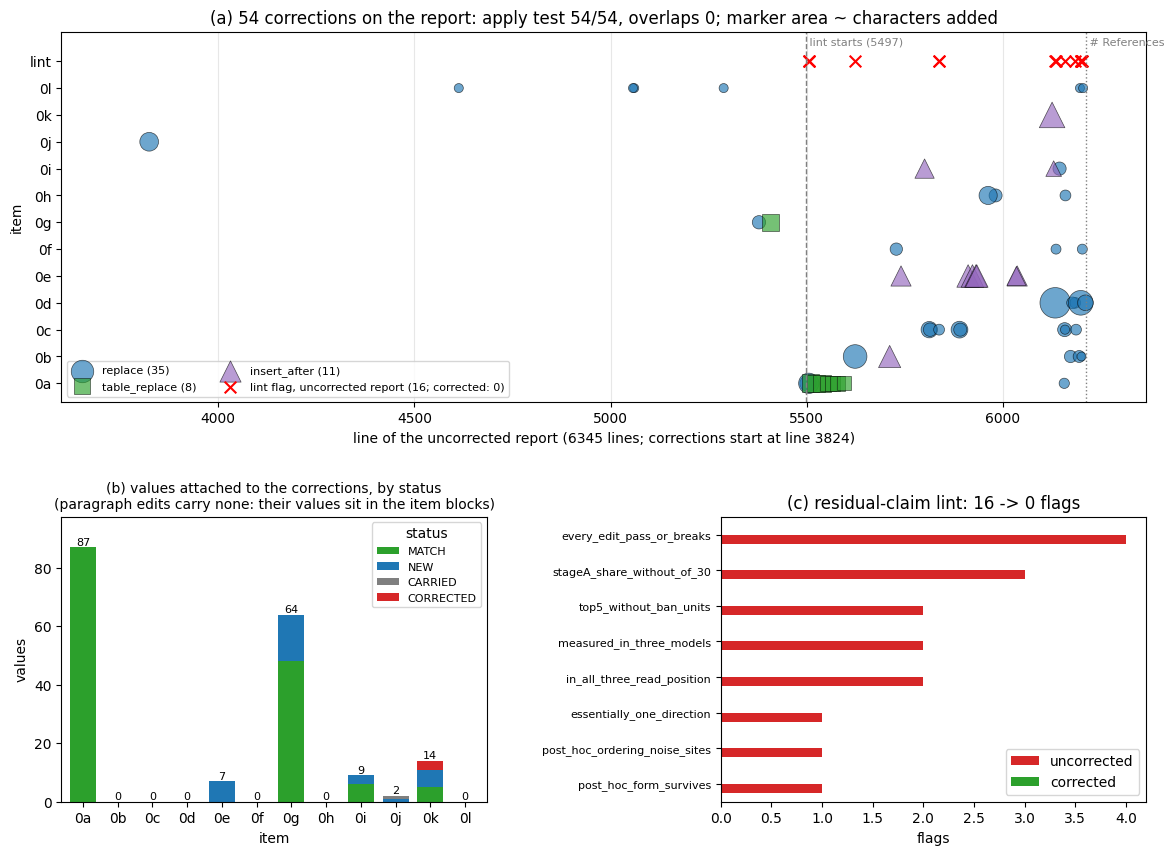

In [18]:
items_order = sorted(RATIONALE)  # 0a .. 0l
ypos = {it: i for i, it in enumerate(items_order)}
kind_style = {"replace": ("o", "tab:blue"), "table_replace": ("s", "tab:green"), "insert_after": ("^", "tab:purple")}
refs_line = next((i + 1 for i, l in enumerate(report_lines) if l.startswith("# References")), len(report_lines))

fig = plt.figure(figsize=(14, 10))
gs = fig.add_gridspec(2, 2, height_ratios=[1.3, 1], hspace=0.35, wspace=0.55)

# (a) report map: one marker per correction at the line where its old_text starts
ax = fig.add_subplot(gs[0, :])
for kind, (mk, col) in kind_style.items():
    cs = [c for c in corr if c["kind"] == kind]
    if not cs:
        continue
    added = [max(len(c["new_text"]) - (0 if kind == "insert_after" else len(c["old_text"])), 0) for c in cs]
    ax.scatter([c["line_at_read"] for c in cs], [ypos[c["item"]] for c in cs], s=[25 + a / 5 for a in added],
               marker=mk, color=col, alpha=0.65, edgecolor="k", linewidth=0.5, label=f"{kind} ({len(cs)})")
flag_lines = [h["line"] for h in lint_before]
ax.scatter(flag_lines, [len(items_order)] * len(flag_lines), marker="x", color="red", s=70,
           label=f"lint flag, uncorrected report ({len(lint_before)}; corrected: {len(lint_after)})")
ax.axvline(5497, color="grey", ls="--", lw=1)
ax.axvline(refs_line, color="grey", ls=":", lw=1)
ax.text(5497, len(items_order) + 0.6, " lint starts (5497)", fontsize=8, color="grey")
ax.text(refs_line, len(items_order) + 0.6, " # References", fontsize=8, color="grey")
ax.set_yticks(range(len(items_order) + 1))
ax.set_yticklabels(items_order + ["lint"])
ax.set_ylim(-0.7, len(items_order) + 1.1)
ax.set_xlim(3600, len(report_lines) + 20)
ax.set_xlabel(f"line of the uncorrected report ({len(report_lines)} lines; corrections start at line "
              f"{min(c['line_at_read'] for c in corr)})")
ax.set_ylabel("item")
ax.set_title(f"(a) {len(corr)} corrections on the report: apply test {apply_res['n_pass']}/{apply_res['n']}, "
             f"overlaps {len(apply_res['overlaps'])}; marker area ~ characters added")
ax.legend(loc="lower left", fontsize=8, ncol=2)
ax.grid(axis="x", alpha=0.3)

# (b) values attached to corrections, by item and status
ax2 = fig.add_subplot(gs[1, 0])
vs = pd.DataFrame([{"item": c["item"], "status": v["status"]} for c in corr for v in c["values"]])
status_cols = {"MATCH": "tab:green", "NEW": "tab:blue", "CARRIED": "tab:gray", "CORRECTED": "tab:red"}
if len(vs):
    tab = (vs.groupby(["item", "status"]).size().unstack(fill_value=0)
             .reindex(index=items_order, columns=list(status_cols), fill_value=0))
    tab.plot(kind="bar", stacked=True, ax=ax2, color=list(status_cols.values()), width=0.75)
    for i, (it, r) in enumerate(tab.iterrows()):
        ax2.text(i, r.sum() + 0.8, str(int(r.sum())), ha="center", fontsize=8)
    ax2.set_ylim(0, tab.sum(axis=1).max() * 1.12)
    ax2.legend(title="status", fontsize=8, loc="upper right")
ax2.set_title("(b) values attached to the corrections, by status\n(paragraph edits carry none: their values sit in the item blocks)", fontsize=10)
ax2.set_xlabel("item")
ax2.set_ylabel("values")
ax2.tick_params(axis="x", rotation=0)

# (c) lint flags by rule, before and after correction
ax3 = fig.add_subplot(gs[1, 1])
lr = pd.DataFrame({"uncorrected": Counter(h["rule"] for h in lint_before),
                   "corrected": Counter(h["rule"] for h in lint_after)}).fillna(0).sort_values("uncorrected")
lr.plot(kind="barh", ax=ax3, color=["tab:red", "tab:green"])
ax3.set_title(f"(c) residual-claim lint: {len(lint_before)} -> {len(lint_after)} flags")
ax3.set_xlabel("flags")
ax3.tick_params(axis="y", labelsize=8)
plt.show()

## Headline statistics, re-derived with `src/stats.py`

The full run computed these from raw rows. Here the same functions run on the counts it recorded (`headline_inputs` in the demo data), and each result is set beside the recorded one:
- **0a, Stage A.** For the seven key cells: the attempted-Y share against the correct-Y share, each with a 95 % Clopper–Pearson interval. Commit0's transfer is the cell's Y share minus its twin's. The validity gate is pass / pass of the twin ≥ 0.8.
- **0a, post-hoc McNemar.** Correct Y under the exchange at blocks 0–35 against the matched-norm random exchange, 30 paired slots per task.
- **0h, NLA.** The unit-level McNemar (20:88). The first unit per sample (0:25). The per-sample sign test (12:38). The task-level sign test (1:3), and the smallest p any test can reach with 5 task clusters.
- **0i, U6.** The exact binomial test of 73/192 BFS from the empty prefix against the natural share 0.305.

In the plot, a gap between the blue (attempted) and orange (correct) intervals is the 0a correction itself: the printed shares count attempts, not working programs.

0a: 5 of 75 Stage A cells fail commit0's pass-ratio gate in the full run


,task,cell,Y,attempted Y,correct Y,transfer,pass ratio,gate ok,as recorded
0,T2 shortest path,X_0-35,bf_spfa,"24/30 [0.61, 0.92]","21/30 [0.51, 0.85]",0.800,0.900,True,True
1,T2 shortest path,X_12-23,bf_spfa,"18/30 [0.41, 0.77]","11/30 [0.20, 0.56]",0.600,0.733,False,True
2,T03 kth smallest,X_0-35,quickselect,"17/30 [0.37, 0.75]","16/30 [0.34, 0.72]",0.567,0.967,True,True
3,T1 grid,X_0-35,dfs,"14/30 [0.28, 0.66]","3/30 [0.02, 0.27]",0.467,0.593,False,True
4,T1 grid,COND,dfs,"10/30 [0.17, 0.53]","7/30 [0.10, 0.42]",0.333,0.889,True,True
5,T2 shortest path,FORCEDX_0-35,bf_spfa,"30/30 [0.88, 1.00]","30/30 [0.88, 1.00]",0.967,1.034,True,True
6,T10 connected components,FORCEDX_0-35,bfs,"28/30 [0.78, 0.99]","24/30 [0.61, 0.92]",0.933,0.867,True,True


,test,counts,p re-derived,p recorded,status_of
0,"0a post-hoc McNemar, correct Y, T2 shortest path",21:0,9.5e-07,9.5e-07,MATCH
1,"0a post-hoc McNemar, correct Y, T03 kth smallest",15:2,0.002,0.002,MATCH
2,"0a post-hoc McNemar, correct Y, T10 connected components",11:0,9.8e-04,9.8e-04,MATCH
3,"0h NLA McNemar, 364 units",20:88,2.3e-11,2.3e-11,MATCH
4,"0h first unit per sample, 104 samples",0:25,6.0e-08,6.0e-08,MATCH
5,0h sign test on per-sample differences,12:38,3.1e-04,3.1e-04,MATCH
6,0h sign test per task (task level),1:3,0.62,0.62,MATCH
7,"0h smallest attainable p, 5 task clusters",5:0,0.062,0.062,MATCH
8,0i U6 exact binomial vs 0.305,73/192,0.028,0.028,MATCH


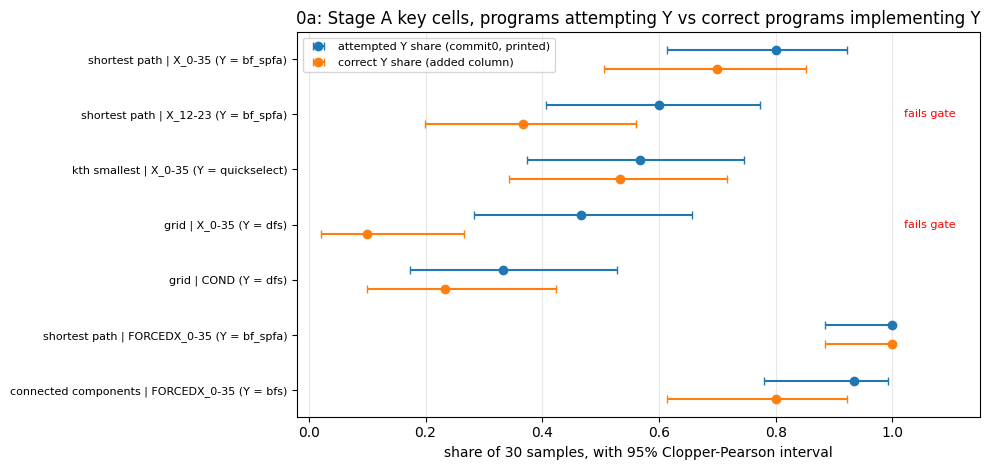

In [19]:
TASK_NAME = {"T03": "kth smallest", "T10": "connected components", "T2": "shortest path", "T05": "two sum",
             "T06": "find duplicate", "T1": "grid"}  # from src/items_qwen.py
hi = data["metadata"]["headline_inputs"]

# 0a: Stage A key cells (attempted vs correct Y, CP intervals, commit0 transfer and pass-ratio gate)
rows = []
for c in hi["stage_a_key_cells"]:
    att_ci, cor_ci = clopper_pearson(c["attempted_Y"], c["n"]), clopper_pearson(c["correct_Y"], c["n"])
    transfer = c["attempted_Y"] / c["n"] - c["twin_attempted_Y"] / c["twin_n"]
    pass_ratio = (c["pass_k"] / c["n"]) / (c["twin_pass_k"] / c["twin_n"])
    gate_ok = pass_ratio >= 0.8 - 1e-12
    rows.append({"task": f"{c['task']} {TASK_NAME[c['task']]}", "cell": c["cell"], "Y": c["Y"],
                 "attempted Y": f"{c['attempted_Y']}/{c['n']} [{att_ci[0]:.2f}, {att_ci[1]:.2f}]",
                 "correct Y": f"{c['correct_Y']}/{c['n']} [{cor_ci[0]:.2f}, {cor_ci[1]:.2f}]",
                 "transfer": round(transfer, 3), "pass ratio": round(pass_ratio, 3), "gate ok": gate_ok,
                 "as recorded": bool(np.allclose(att_ci, c["Y_ci95_cp"]) and np.allclose(cor_ci, c["correct_Y_ci95_cp"])
                                     and abs(transfer - c["transfer"]) < 1e-9 and abs(pass_ratio - c["pass_ratio"]) < 1e-9
                                     and gate_ok == c["gate_ok"])})
print(f"0a: {hi['n_cells_failing_gate']} of {hi['n_cells_total']} Stage A cells fail commit0's pass-ratio gate in the full run")
display(pd.DataFrame(rows))

# 0a, 0h, 0i: exact tests on the recorded counts
nla, u6 = hi["nla"], hi["u6"]
tests = [(f"0a post-hoc McNemar, correct Y, {t} {TASK_NAME[t]}", f"{r['correct_b']}:{r['correct_c']}",
          mcnemar_exact(r["correct_b"], r["correct_c"]), r["correct_p"]) for t, r in hi["mr_posthoc_correct_Y"].items()]
tests += [
    (f"0h NLA McNemar, {nla['n_units']} units", f"{nla['b']}:{nla['c']}", mcnemar_exact(nla["b"], nla["c"]), nla["p"]),
    (f"0h first unit per sample, {nla['n_samples']} samples", f"{nla['one_unit_first']['b']}:{nla['one_unit_first']['c']}",
     mcnemar_exact(nla["one_unit_first"]["b"], nla["one_unit_first"]["c"]), nla["one_unit_first"]["p"]),
    ("0h sign test on per-sample differences", f"{nla['sign_test_per_sample']['n_pos']}:{nla['sign_test_per_sample']['n_neg']}",
     binom_two_sided(nla["sign_test_per_sample"]["n_pos"], nla["sign_test_per_sample"]["n_pos"] + nla["sign_test_per_sample"]["n_neg"]),
     nla["sign_test_per_sample"]["p"]),
    ("0h sign test per task (task level)", f"{nla['task_level_sign']['n_pos']}:{nla['task_level_sign']['n_neg']}",
     binom_two_sided(nla["task_level_sign"]["n_pos"], nla["task_level_sign"]["n_pos"] + nla["task_level_sign"]["n_neg"]),
     nla["task_level_sign"]["p"]),
    (f"0h smallest attainable p, {len(nla['clusters'])} task clusters", f"{len(nla['clusters'])}:0",
     sign_test_floor(len(nla["clusters"])), nla["cluster_floor_p"]),
    (f"0i U6 exact binomial vs {u6['s3_bfs_share']}", f"{u6['k']}/{u6['t0_n']}",
     binom_two_sided(u6["k"], u6["t0_n"], u6["s3_bfs_share"]), u6["exact_binomial_p"]),
]
tt = pd.DataFrame(tests, columns=["test", "counts", "p re-derived", "p recorded"])
tt["status_of"] = [status_of(r, c, "p") for c, r in zip(tt["p re-derived"], tt["p recorded"])]
display(tt.assign(**{"p re-derived": tt["p re-derived"].map(fmt_p), "p recorded": tt["p recorded"].map(fmt_p)}))

# forest plot: attempted vs correct Y share per key cell (the 0a correction)
fig, ax = plt.subplots(figsize=(10, 4.8))
labels = []
for i, c in enumerate(hi["stage_a_key_cells"]):
    for off, k, col, lab in ((-0.17, "attempted_Y", "tab:blue", "attempted Y share (commit0, printed)"),
                             (0.17, "correct_Y", "tab:orange", "correct Y share (added column)")):
        lo, hi_ = clopper_pearson(c[k], c["n"])
        p = c[k] / c["n"]
        ax.errorbar(p, i + off, xerr=[[p - lo], [hi_ - p]], fmt="o", color=col, capsize=3, label=lab if i == 0 else None)
    if not c["gate_ok"]:
        ax.text(1.02, i, "fails gate", color="red", fontsize=8, va="center")
    labels.append(f"{TASK_NAME[c['task']]} | {c['cell']} (Y = {c['Y']})")
ax.set_yticks(range(len(labels)))
ax.set_yticklabels(labels, fontsize=8)
ax.invert_yaxis()
ax.set_xlim(-0.02, 1.15)
ax.set_xlabel("share of 30 samples, with 95% Clopper-Pearson interval")
ax.set_title("0a: Stage A key cells, programs attempting Y vs correct programs implementing Y")
ax.legend(loc="upper left", fontsize=8)
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

## What the demo covers, and how to run the full evaluation

**Reproduced here with the original code:**
- the registry IDs and line numbers;
- the apply test and the corrected report with its diff;
- the residual-claim lint, both before and after correction;
- the value-status rule;
- `corrections.json`, the values ledger, `corrections_index.csv` and `lint.csv`;
- metrics M1/M2 and the `corrections` dataset rows;
- the exact tests behind the headline numbers of 0a, 0h and 0i.

**Not reproduced here:**
- the items' recomputation from raw rows (about 40 MB across four experiments);
- the three blind LLM judges and the live web pass of 0i and 0k;
- metrics M3–M12;
- the occurrence ledger, which needs the full report;
- the two independent audits: `audit/rederive.py` (520 checks, 7 placebos) and `audit/headline_check.py` (35 checks, 7 placebos).

To run everything, use the artifact's own folder (`eval.py`, `src/`, `audit/`, and the vendored `inputs/`):

```bash
bash restore.sh                     # .venv with the exact versions pinned in pyproject.toml
uv run eval.py --stages offline     # about 20 s; reuses the cached judge and web results; no network, no spend
python3 -I audit/rederive.py        # the independent standard-library audit
python3 -I audit/headline_check.py  # the headline re-derivation with placebos
uv run eval.py --stages all         # optional: re-calls the paid judges and the live web pass (about USD 0.08)
```